# Notebook 1: Autoencoder (AE)
**Assignment-02 | Activity A (CO3): Image Reconstruction** | Prepared by: Manmath (Research & Code Lead)

| | |
|---|---|
| **What to run** | Run all cells top to bottom (no edits needed). |
| **Where output appears** | Cell 5 shows original vs reconstructed images (saved as `A2_AE_recon.png`). |
| **Expected runtime** | about 1-2 min on T4 GPU |
| **Runtime setting** | Runtime -> Change runtime type -> **T4 GPU**, then **Runtime -> Run all** |

> Ready-made implementation written in Keras, tutorial style. Nothing is trained from scratch beyond a short demo run.

## 1. Idea in brief
An autoencoder learns to **compress** an image into a small vector (the *latent code*) with an **encoder** and rebuild it with a **decoder**.
Training minimises the reconstruction error (here Mean Squared Error). The code is a single point per image, so the latent space is not regularised.

## 2. Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (switch runtime to T4 GPU)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load data and choose input images

In [2]:
# Fashion-MNIST: 28x28 grayscale clothing images (clear textures, so blur is easy to see)
(x_train, _), (x_test, _) = keras.datasets.fashion_mnist.load_data()
x_train = np.expand_dims(x_train.astype("float32") / 255.0, -1)
x_test = np.expand_dims(x_test.astype("float32") / 255.0, -1)
print("train:", x_train.shape, "test:", x_test.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
train: (60000, 28, 28, 1) test: (10000, 28, 28, 1)


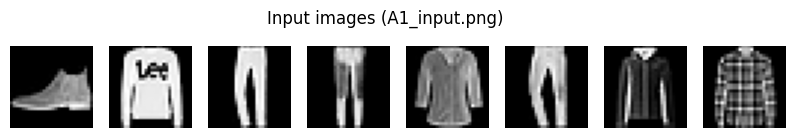

In [3]:
# SAME input images are used in the AE and VAE notebooks, so the comparison is fair.
SAMPLE_IDX = [0, 1, 2, 3, 4, 5, 6, 7]
inputs = x_test[SAMPLE_IDX]

# Optional: use your own image instead (set USE_CUSTOM_IMAGE = True and upload a file in Colab).
USE_CUSTOM_IMAGE = False
CUSTOM_PATH = "my_image.png"
if USE_CUSTOM_IMAGE:
    from PIL import Image
    img = Image.open(CUSTOM_PATH).convert("L").resize((28, 28))
    inputs = np.expand_dims(np.array(img, dtype="float32")[None] / 255.0, -1)

plt.figure(figsize=(10, 1.6))
for i in range(len(inputs)):
    plt.subplot(1, len(inputs), i + 1)
    plt.imshow(inputs[i].squeeze(), cmap="gray"); plt.axis("off")
plt.suptitle("Input images (A1_input.png)")
plt.savefig("A1_input.png", dpi=200, bbox_inches="tight"); plt.show()

## 4. Build and train the Autoencoder

In [4]:
LATENT_DIM = 16   # same bottleneck size as the VAE notebook

encoder = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2D(64, 3, strides=2, padding="same", activation="relu"),
    layers.Flatten(),
    layers.Dense(LATENT_DIM),
], name="encoder")

decoder = keras.Sequential([
    layers.Input((LATENT_DIM,)),
    layers.Dense(7 * 7 * 64, activation="relu"),
    layers.Reshape((7, 7, 64)),
    layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2DTranspose(1, 3, padding="same", activation="sigmoid"),
], name="decoder")

autoencoder = keras.Sequential([encoder, decoder], name="autoencoder")
autoencoder.compile(optimizer="adam", loss="mse")
autoencoder.summary()

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder (Sequential)            │ (None, 16)             │        69,008 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Sequential)            │ (None, 28, 28, 1)      │       108,993 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 178,001 (695.32 KB)

 Trainable params: 178,001 (695.32 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
469/469 - 19s - 40ms/step - loss: 0.0334 - val_loss: 0.0157
Epoch 2/10
469/469 - 3s - 7ms/step - loss: 0.0139 - val_loss: 0.0127
Epoch 3/10
469/469 - 3s - 7ms/step - loss: 0.0121 - val_loss: 0.0118
Epoch 4/10
469/469 - 3s - 7ms/step - loss: 0.0114 - val_loss: 0.0112
Epoch 5/10
469/469 - 4s - 8ms/step - loss: 0.0109 - val_loss: 0.0109
Epoch 6/10
469/469 - 3s - 7ms/step - loss: 0.0105 - val_loss: 0.0105
Epoch 7/10
469/469 - 3s - 7ms/step - loss: 0.0103 - val_loss: 0.0103
Epoch 8/10
469/469 - 3s - 7ms/step - loss: 0.0101 - val_loss: 0.0102
Epoch 9/10
469/469 - 4s - 8ms/step - loss: 0.0099 - val_loss: 0.0100
Epoch 10/10
469/469 - 3s - 7ms/step - loss: 0.0098 - val_loss: 0.0099
Training time: 49.7 s


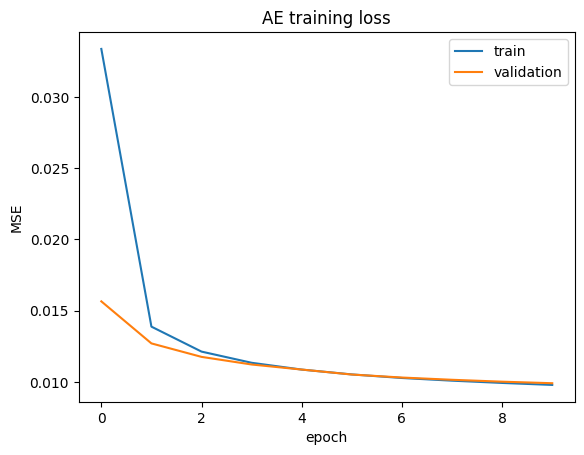

In [5]:
EPOCHS = 10
start = time.time()
history = autoencoder.fit(x_train, x_train, epochs=EPOCHS, batch_size=128,
                          validation_data=(x_test, x_test), verbose=2)
train_time = time.time() - start
print(f"Training time: {train_time:.1f} s")

plt.plot(history.history["loss"], label="train"); plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.title("AE training loss"); plt.legend(); plt.show()

## 5. Reconstruct the input images (screenshot this cell)

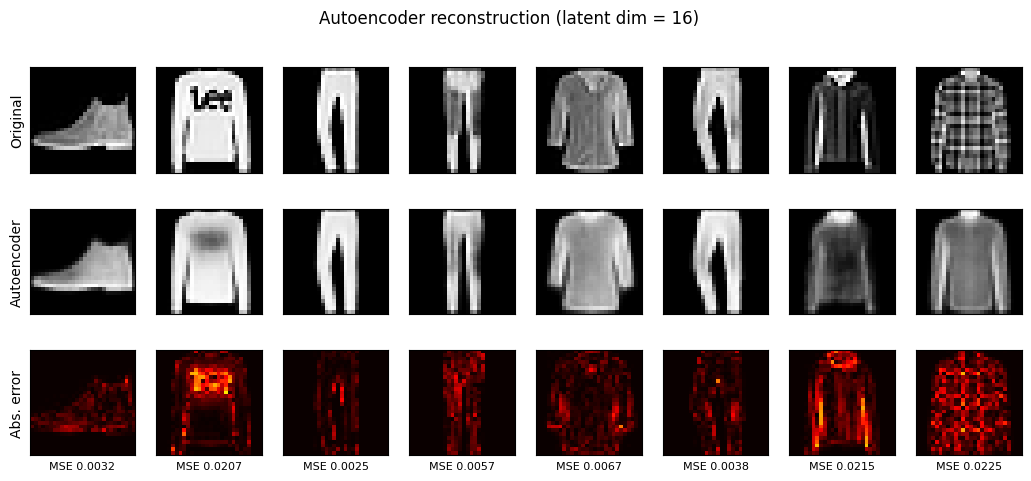

Average MSE over the shown images: 0.01083


In [6]:
recon = autoencoder.predict(inputs, verbose=0)
mse = np.mean((inputs - recon) ** 2, axis=(1, 2, 3))

n = len(inputs)
fig, axes = plt.subplots(3, n, figsize=(1.6 * n, 5.2))
for i in range(n):
    axes[0, i].imshow(inputs[i].squeeze(), cmap="gray")
    axes[1, i].imshow(recon[i].squeeze(), cmap="gray")
    axes[2, i].imshow(np.abs(inputs[i] - recon[i]).squeeze(), cmap="hot", vmin=0, vmax=1)
    axes[2, i].set_xlabel(f"MSE {mse[i]:.4f}", fontsize=8)
    for r in range(3):
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])
axes[0, 0].set_ylabel("Original"); axes[1, 0].set_ylabel("Autoencoder"); axes[2, 0].set_ylabel("Abs. error")
fig.suptitle("Autoencoder reconstruction (latent dim = %d)" % LATENT_DIM)
plt.savefig("A2_AE_recon.png", dpi=200, bbox_inches="tight"); plt.show()
print("Average MSE over the shown images: %.5f" % mse.mean())

## 6. Can an Autoencoder generate *new* images?
We decode random latent vectors. Because the AE never forces its latent space to follow a known distribution, random codes usually give meaningless output.

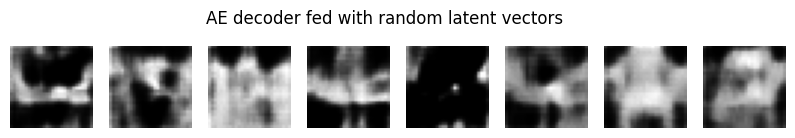

In [7]:
z = np.random.normal(size=(8, LATENT_DIM)).astype("float32")
samples = decoder.predict(z, verbose=0)
plt.figure(figsize=(10, 1.6))
for i in range(8):
    plt.subplot(1, 8, i + 1); plt.imshow(samples[i].squeeze(), cmap="gray"); plt.axis("off")
plt.suptitle("AE decoder fed with random latent vectors"); plt.savefig("A2b_AE_random.png", dpi=200, bbox_inches="tight"); plt.show()

## 7. Observation notes (copy into the Observation Table)
- Blurring: ______  | Distortion: ______  | Loss of detail: ______
- Runtime: see "Training time" above.
- Random latent vectors: ______